<a href="https://colab.research.google.com/github/kulanigayathree/J26-IT-364/blob/model%2FOil-Spill-Detection/notebooks/oil-spill/C4_04b_tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# C4 – Step 5b: Model tuning (imbalance + hyperparameters + threshold)
**Karanne:** C4_04 eke train karapu **Random Forest** saha **XGBoost** thawath hondaa karanna balanawa:

| Kotasa | Karana de |
|---|---|
| **A. Imbalance methods** | None / Class weights / SMOTE / Undersampling, hondama eka mokakda? |
| **B. Hyperparameter tuning** | Random Search eken hondama settings (trees, depth, learning rate…) |
| **C. Threshold tuning** | 0.5 wenuwata hondama "oil" cut-off eka |
| **D. Kalin vs Passe** | Test set eken anthima sasandanaya (**ekama warak**) |

⚠️ **Wadagath neethiya:** A, B, C okkoma karanne **train data eke cross-validation** walin witharai. **Test data** balanne **D eke ekama warak**. (Leakage naha ✅)

✅ C4_04 eke models **wenas wenne naha**. Tuned models **aluth nam walin** save wenawa.

⏳ Mulu notebook ekama **minutes 15–25** wage. **Runtime → Run all** karala balan inna. Tab eka close karanna epa.

## 1. Setup: Drive connect + library install

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
!pip -q install imbalanced-learn

Mounted at /content/drive


## 2. Data load karanna (C4_04 ekama data, ekama split eka)

In [ ]:
import os, sys, time, json, warnings, numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
DRIVE_DIR = '/content/drive/MyDrive/C4_OilSpill'
DATA_DIR, RES_DIR, MODEL_DIR = f'{DRIVE_DIR}/data', f'{DRIVE_DIR}/results', f'{DRIVE_DIR}/models'
sys.path.insert(0, DRIVE_DIR)
from c4_features import FEATURES

data = pd.read_csv(f'{DATA_DIR}/features.csv')
train, test = data[data.split == 'train'], data[data.split == 'test']
X_train, y_train, groups = train[FEATURES], train['y'], train['start_time']
X_test,  y_test          = test[FEATURES],  test['y']
neg, pos = (y_train == 0).sum(), (y_train == 1).sum()
SPW = neg / pos   # look-alike : oil ratio

print(f'Train : {len(train):,} patches (oil {pos:,}) | Test : {len(test):,} patches (oil {y_test.sum():,})')
print(f'Imbalance  1 : {SPW:.1f}')

Train : 26,301 patches (oil 4,138) | Test : 5,683 patches (oil 621)
Imbalance  1 : 5.4


## 3. 📏 "Kalin" lakunu (C4_04 models, threshold 0.5)
Drive eke save karapu C4_04 models load karala test eke lakunu balanawa. Meka thamai **sasandanaya karana mulika lakuna (baseline)**.

In [ ]:
from sklearn.metrics import (precision_score, recall_score, f1_score, accuracy_score,
                             roc_auc_score, confusion_matrix)

def scores(name, y_true, prob, thr):
    pred = (prob >= thr).astype(int)
    return dict(Model=name, Threshold=round(float(thr), 2),
                Precision=precision_score(y_true, pred, zero_division=0),
                Recall=recall_score(y_true, pred), F1=f1_score(y_true, pred),
                ROC_AUC=roc_auc_score(y_true, prob), Accuracy=accuracy_score(y_true, pred))

before = {'Random Forest': joblib.load(f'{MODEL_DIR}/random_forest.pkl'),
          'XGBoost':       joblib.load(f'{MODEL_DIR}/xgboost.pkl')}
before_rows = [scores(f'{n} (C4_04)', y_test, m.predict_proba(X_test)[:, 1], 0.5) for n, m in before.items()]
pd.DataFrame(before_rows).set_index('Model').round(3)

,Threshold,Precision,Recall,F1,ROC_AUC,Accuracy
Model,,,,,,
Random Forest (C4_04),0.5,0.790,0.671,0.726,0.949,0.945
XGBoost (C4_04),0.5,0.632,0.823,0.715,0.958,0.928


## 4. 🅰️ Imbalance methods sasandanaya (5-fold GroupKFold CV)
| Method | Karana de |
|---|---|
| **None** | Imbalance eka gana kisi deyak karanne naha |
| **Class weights** | Oil waradi kalama wadi danduwamak (C4_04 eke use kale meka) |
| **SMOTE** | Oil patches athara **aluth oil examples** hadanawa (train fold eke witharai) |
| **Undersampling** | Look-alikes samahara ain karala oil ganata samana karanawa |

⏳ Minutes 4–6 wage. (Ikmanata iwara wenna RF trees 150k use karanawa.)

In [ ]:
from sklearn.model_selection import GroupKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from imblearn.pipeline import make_pipeline as imb_pipeline
from imblearn.over_sampling import SMOTE
from imblearn.under_sampling import RandomUnderSampler

gkf5 = GroupKFold(n_splits=5)
rf_base  = lambda cw=None: RandomForestClassifier(n_estimators=150, min_samples_leaf=2, class_weight=cw,
                                                  n_jobs=-1, random_state=42)
xgb_base = lambda spw=1.0: XGBClassifier(n_estimators=400, max_depth=6, learning_rate=0.05, subsample=0.8,
                                         colsample_bytree=0.8, scale_pos_weight=spw, eval_metric='logloss',
                                         n_jobs=-1, random_state=42)
methods = {
    'None':          {'Random Forest': rf_base(),                     'XGBoost': xgb_base()},
    'Class weights': {'Random Forest': rf_base('balanced_subsample'), 'XGBoost': xgb_base(SPW)},
    'SMOTE':         {'Random Forest': imb_pipeline(SMOTE(random_state=42), rf_base()),
                      'XGBoost':       imb_pipeline(SMOTE(random_state=42), xgb_base())},
    'Undersampling': {'Random Forest': imb_pipeline(RandomUnderSampler(random_state=42), rf_base()),
                      'XGBoost':       imb_pipeline(RandomUnderSampler(random_state=42), xgb_base())},
}
imb_rows = []
for method, ms in methods.items():
    for name, m in ms.items():
        t0 = time.time()
        s = cross_val_score(m, X_train, y_train, groups=groups, cv=gkf5, scoring='f1')
        imb_rows.append(dict(Method=method, Model=name, CV_F1=s.mean(), CV_std=s.std()))
        print(f'{method:14s} {name:14s} CV F1 = {s.mean():.3f} ± {s.std():.3f}   ({time.time()-t0:.0f}s)')

imb = pd.DataFrame(imb_rows)
imb.round(3).to_csv(f'{RES_DIR}/04b_imbalance_methods.csv', index=False)
imb_table = imb.pivot(index='Method', columns='Model', values='CV_F1').loc[list(methods)].round(3)
imb_table

None           Random Forest  CV F1 = 0.760 ± 0.043   (103s)
None           XGBoost        CV F1 = 0.774 ± 0.044   (13s)
Class weights  Random Forest  CV F1 = 0.762 ± 0.046   (73s)
Class weights  XGBoost        CV F1 = 0.759 ± 0.044   (14s)
SMOTE          Random Forest  CV F1 = 0.736 ± 0.044   (130s)
SMOTE          XGBoost        CV F1 = 0.758 ± 0.041   (18s)
Undersampling  Random Forest  CV F1 = 0.703 ± 0.044   (19s)
Undersampling  XGBoost        CV F1 = 0.727 ± 0.044   (10s)


Model,Random Forest,XGBoost
Method,,
None,0.760,0.774
Class weights,0.762,0.759
SMOTE,0.736,0.758
Undersampling,0.703,0.727


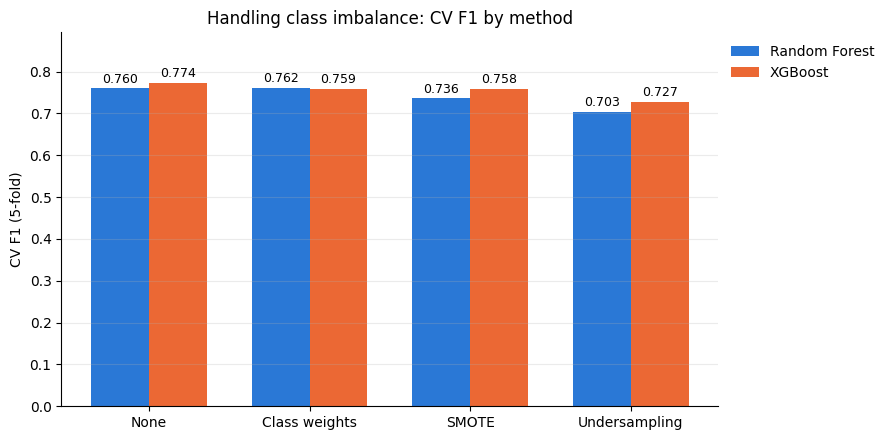

🏆 Saamaanyen hondama imbalance method eka: None


In [ ]:
fig, ax = plt.subplots(figsize=(9, 4.5))
x = np.arange(len(imb_table)); w = 0.36
for i, (name, color) in enumerate([('Random Forest', '#2a78d6'), ('XGBoost', '#eb6834')]):
    vals = imb_table[name].values
    bars = ax.bar(x + (i - 0.5) * w, vals, w, label=name, color=color)
    ax.bar_label(bars, fmt='%.3f', fontsize=9, padding=2)
ax.set_xticks(x); ax.set_xticklabels(imb_table.index)
ax.set_ylabel('CV F1 (5-fold)'); ax.set_ylim(0, min(1, imb_table.values.max() + 0.12))
ax.set_title('Handling class imbalance: CV F1 by method')
ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1, 1)); ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='y', alpha=0.25)
plt.tight_layout(); plt.savefig(f'{RES_DIR}/04b_imbalance_methods.png', dpi=120); plt.show()

best_method = imb.groupby('Method')['CV_F1'].mean().idxmax()
print(f'🏆 Saamaanyen hondama imbalance method eka: {best_method}')

## 5. 🅱️ Hyperparameter tuning (Random Search + 3-fold GroupKFold CV)
Random settings combinations godak try karala **CV F1 wadima** eka thoranawa.
- **Random Forest:** combinations 10k (trees, depth, leaf size, features per split, class weight)
- **XGBoost:** combinations 25k (trees, depth, learning rate, sampling, min child weight, scale_pos_weight)

Class weights / scale_pos_weight search eke athule thiyena nisa imbalance ekath handle wenawa.

⏳ Minutes 8–15 wage. Meka thamai digama kotasa. ☕

In [ ]:
from sklearn.model_selection import RandomizedSearchCV
gkf3 = GroupKFold(n_splits=3)

rf_space = {
    'n_estimators':     [200, 300, 500],
    'max_depth':        [None, 12, 20, 30],
    'min_samples_leaf': [1, 2, 4, 8],
    'max_features':     ['sqrt', 'log2', 0.5],
    'class_weight':     ['balanced', 'balanced_subsample'],
}
t0 = time.time()
rf_search = RandomizedSearchCV(RandomForestClassifier(n_jobs=-1, random_state=42), rf_space,
                               n_iter=10, scoring='f1', cv=gkf3, random_state=42, n_jobs=1, refit=True)
rf_search.fit(X_train, y_train, groups=groups)
print(f'🌲 Random Forest  best CV F1 = {rf_search.best_score_:.3f}   ({time.time()-t0:.0f}s)')
print('   best settings:', rf_search.best_params_)

🌲 Random Forest  best CV F1 = 0.758   (747s)
   best settings: {'n_estimators': 500, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': 20, 'class_weight': 'balanced'}


In [ ]:
xgb_space = {
    'n_estimators':     [200, 400, 600, 800],
    'max_depth':        [3, 4, 5, 6, 8],
    'learning_rate':    [0.03, 0.05, 0.1],
    'subsample':        [0.7, 0.8, 1.0],
    'colsample_bytree': [0.6, 0.8, 1.0],
    'min_child_weight': [1, 3, 5],
    'scale_pos_weight': [1.0, float(np.sqrt(SPW)), float(SPW)],
}
t0 = time.time()
xgb_search = RandomizedSearchCV(XGBClassifier(eval_metric='logloss', n_jobs=-1, random_state=42), xgb_space,
                                n_iter=25, scoring='f1', cv=gkf3, random_state=42, n_jobs=1, refit=True)
xgb_search.fit(X_train, y_train, groups=groups)
print(f'⚡ XGBoost  best CV F1 = {xgb_search.best_score_:.3f}   ({time.time()-t0:.0f}s)')
print('   best settings:', xgb_search.best_params_)

tuned = {'Random Forest': rf_search.best_estimator_, 'XGBoost': xgb_search.best_estimator_}
pd.DataFrame([dict(Model='Random Forest', **{k: str(v) for k, v in rf_search.best_params_.items()}),
              dict(Model='XGBoost', **{k: str(v) for k, v in xgb_search.best_params_.items()})]
             ).to_csv(f'{RES_DIR}/04b_best_params.csv', index=False)

⚡ XGBoost  best CV F1 = 0.774   (186s)
   best settings: {'subsample': 0.8, 'scale_pos_weight': 1.0, 'n_estimators': 600, 'min_child_weight': 1, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 1.0}


## 6. 🅲 Threshold tuning
Train data eke **5-fold CV predictions** (out-of-fold) gena, threshold **0.05 – 0.95** okkoma try karala **F1 wadima** threshold eka thoranawa.
- Threshold ⬇️ → Recall ⬆️ (oil wadiyen allanawa), Precision ⬇️ (boru alarms wadi)
- Threshold ⬆️ → Precision ⬆️, Recall ⬇️

Random Forest  CV F1 @0.50 = 0.760  →  best threshold 0.47  CV F1 = 0.763   (230s)
XGBoost        CV F1 @0.50 = 0.773  →  best threshold 0.44  CV F1 = 0.775   (17s)


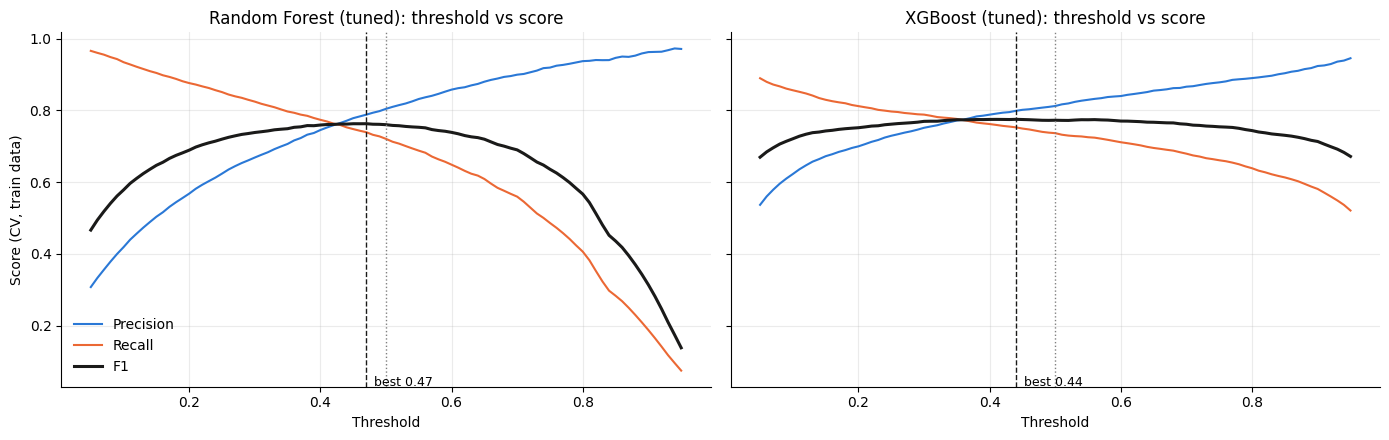

In [ ]:
from sklearn.model_selection import cross_val_predict
from sklearn.base import clone

thresholds = np.round(np.arange(0.05, 0.951, 0.01), 2)
best_thr, oof_f1, curves = {}, {}, {}
for name, m in tuned.items():
    t0 = time.time()
    oof = cross_val_predict(clone(m), X_train, y_train, groups=groups, cv=gkf5, method='predict_proba')[:, 1]
    P = [precision_score(y_train, oof >= t, zero_division=0) for t in thresholds]
    R = [recall_score(y_train, oof >= t) for t in thresholds]
    F = [f1_score(y_train, oof >= t) for t in thresholds]
    i = int(np.argmax(F))
    best_thr[name], oof_f1[name], curves[name] = float(thresholds[i]), F[i], (P, R, F)
    f05 = F[int(np.where(thresholds == 0.5)[0][0])]
    print(f'{name:14s} CV F1 @0.50 = {f05:.3f}  →  best threshold {thresholds[i]:.2f}  CV F1 = {F[i]:.3f}   ({time.time()-t0:.0f}s)')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (name, (P, R, F)) in zip(axes, curves.items()):
    ax.plot(thresholds, P, color='#2a78d6', label='Precision')
    ax.plot(thresholds, R, color='#eb6834', label='Recall')
    ax.plot(thresholds, F, color='#1a1a19', lw=2.2, label='F1')
    ax.axvline(0.5, color='grey', ls=':', lw=1)
    ax.axvline(best_thr[name], color='#1a1a19', ls='--', lw=1)
    ax.text(best_thr[name], 0.03, f'  best {best_thr[name]:.2f}', fontsize=9)
    ax.set_title(f'{name} (tuned): threshold vs score'); ax.set_xlabel('Threshold')
    ax.spines[['top', 'right']].set_visible(False); ax.grid(alpha=0.25)
axes[0].set_ylabel('Score (CV, train data)'); axes[0].legend(frameon=False)
plt.tight_layout(); plt.savefig(f'{RES_DIR}/04b_threshold_tuning.png', dpi=120); plt.show()

## 7. 🅳 Kalin vs Passe: TEST set eken (ekama warak!)
Hama model ekakatama:
1. **C4_04** (kalin settings, threshold 0.5)
2. **Tuned** settings, threshold 0.5
3. **Tuned** settings + **hondama threshold** eka ⭐

In [ ]:
rows = list(before_rows)
for name, m in tuned.items():
    prob = m.predict_proba(X_test)[:, 1]
    rows.append(scores(f'{name} (tuned)', y_test, prob, 0.5))
    rows.append(scores(f'{name} (tuned + threshold)', y_test, prob, best_thr[name]))
final = pd.DataFrame(rows).set_index('Model').round(3)
final.to_csv(f'{RES_DIR}/04b_tuning_comparison.csv')

# Hondama model eka thoranne CV walin (test eken nemei -> leakage naha)
best_name = max(oof_f1, key=oof_f1.get)
best_label = f'{best_name} (tuned + threshold)'
print(f'🏆 Hondama model eka (CV F1 anuwa): {best_label}  threshold = {best_thr[best_name]:.2f}')
for name in tuned:
    a, b = final.loc[f'{name} (C4_04)', 'F1'], final.loc[f'{name} (tuned + threshold)', 'F1']
    msg = 'diyunu una ✅' if b > a + 0.005 else ('wenasak naha ➖' if abs(b - a) <= 0.005 else 'tikak adu una ⚠️ (honest widiyata report karanna)')
    print(f'   {name:14s} test F1  {a:.3f} → {b:.3f}  ({b - a:+.3f})  {msg}')
final

🏆 Hondama model eka (CV F1 anuwa): XGBoost (tuned + threshold)  threshold = 0.44
   Random Forest  test F1  0.726 → 0.734  (+0.008)  diyunu una ✅
   XGBoost        test F1  0.715 → 0.743  (+0.028)  diyunu una ✅


,Threshold,Precision,Recall,F1,ROC_AUC,Accuracy
Model,,,,,,
Random Forest (C4_04),0.50,0.790,0.671,0.726,0.949,0.945
XGBoost (C4_04),0.50,0.632,0.823,0.715,0.958,0.928
Random Forest (tuned),0.50,0.790,0.678,0.730,0.949,0.945
Random Forest (tuned + threshold),0.47,0.772,0.699,0.734,0.949,0.945
XGBoost (tuned),0.50,0.799,0.686,0.738,0.955,0.947
XGBoost (tuned + threshold),0.44,0.776,0.713,0.743,0.955,0.946


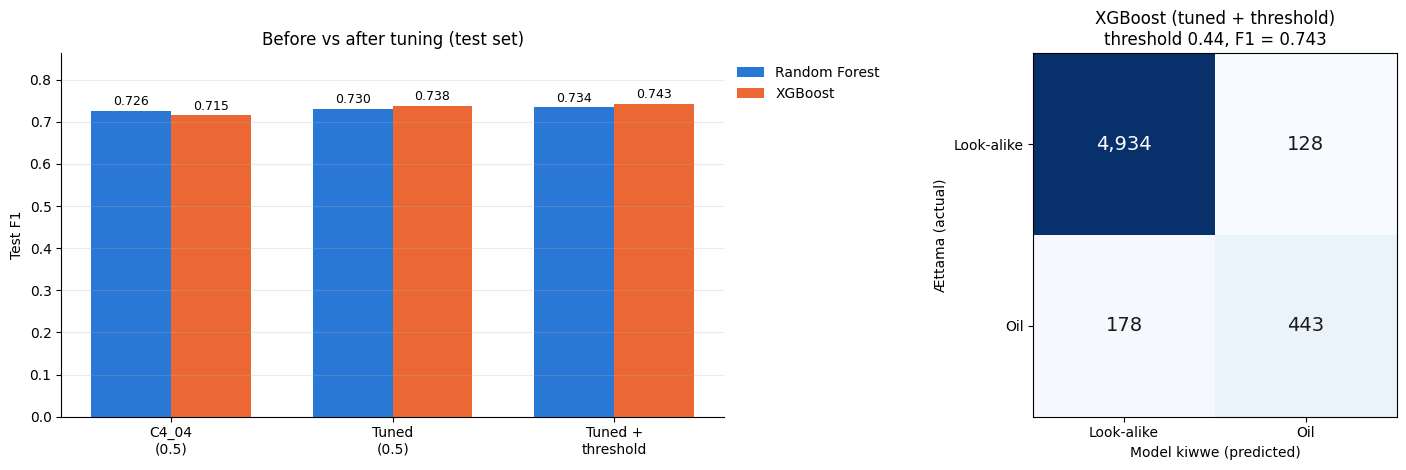

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={'width_ratios': [1.25, 1]})
ax = axes[0]
labels = ['C4_04\n(0.5)', 'Tuned\n(0.5)', 'Tuned +\nthreshold']
x = np.arange(3); w = 0.36
for i, (name, color) in enumerate([('Random Forest', '#2a78d6'), ('XGBoost', '#eb6834')]):
    vals = [final.loc[f'{name} (C4_04)', 'F1'], final.loc[f'{name} (tuned)', 'F1'],
            final.loc[f'{name} (tuned + threshold)', 'F1']]
    bars = ax.bar(x + (i - 0.5) * w, vals, w, label=name, color=color)
    ax.bar_label(bars, fmt='%.3f', fontsize=9, padding=2)
ax.set_xticks(x); ax.set_xticklabels(labels); ax.set_ylabel('Test F1')
ax.set_ylim(0, min(1, final['F1'].max() + 0.12)); ax.legend(frameon=False, loc='upper left', bbox_to_anchor=(1, 1))
ax.set_title('Before vs after tuning (test set)')
ax.spines[['top', 'right']].set_visible(False); ax.grid(axis='y', alpha=0.25)

ax = axes[1]
prob = tuned[best_name].predict_proba(X_test)[:, 1]
cm = confusion_matrix(y_test, (prob >= best_thr[best_name]).astype(int))
ax.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        ax.text(j, i, f'{cm[i, j]:,}', ha='center', va='center', fontsize=14,
                color='white' if cm[i, j] > cm.max() / 2 else '#1a1a19')
ax.set_xticks([0, 1]); ax.set_xticklabels(['Look-alike', 'Oil'])
ax.set_yticks([0, 1]); ax.set_yticklabels(['Look-alike', 'Oil'])
ax.set_xlabel('Model kiwwe (predicted)'); ax.set_ylabel('Ættama (actual)')
ax.set_title(f'{best_label}\nthreshold {best_thr[best_name]:.2f}, F1 = {final.loc[best_label, "F1"]:.3f}')
plt.tight_layout(); plt.savefig(f'{RES_DIR}/04b_before_after.png', dpi=120); plt.show()

## 8. Tuned models Drive eke save karanna (frontend ekata)
C4_04 models **makanne naha**. Aluth files: `random_forest_tuned.pkl`, `xgboost_tuned.pkl`.
`model_info.json` eka update wenawa → frontend eka **hondama model eka + threshold eka** automatically gannawa.

In [ ]:
tuned_files = {'Random Forest (tuned)': 'random_forest_tuned.pkl', 'XGBoost (tuned)': 'xgboost_tuned.pkl'}
joblib.dump(tuned['Random Forest'], f'{MODEL_DIR}/random_forest_tuned.pkl')
joblib.dump(tuned['XGBoost'],       f'{MODEL_DIR}/xgboost_tuned.pkl')

with open(f'{MODEL_DIR}/model_info.json') as f:
    meta = json.load(f)
meta['files'].update(tuned_files)
thr = {n: 0.5 for n in meta['files']}
thr.update({'Random Forest (tuned)': best_thr['Random Forest'], 'XGBoost (tuned)': best_thr['XGBoost']})
meta['thresholds'] = thr
meta['best_model'] = f'{best_name} (tuned)'
meta['tuned_metrics'] = final.reset_index().to_dict(orient='records')
meta['best_params'] = {'Random Forest': {k: (v if not isinstance(v, np.generic) else v.item())
                                         for k, v in rf_search.best_params_.items()},
                       'XGBoost': {k: (v if not isinstance(v, np.generic) else v.item())
                                   for k, v in xgb_search.best_params_.items()}}
with open(f'{MODEL_DIR}/model_info.json', 'w') as f:
    json.dump(meta, f, indent=2, default=str)
print('Saved ✅', sorted(os.listdir(MODEL_DIR)))
print('Frontend best model:', meta['best_model'], '| threshold', thr[meta['best_model']])

Saved ✅ ['logistic_regression.pkl', 'model_info.json', 'random_forest.pkl', 'random_forest_tuned.pkl', 'xgboost.pkl', 'xgboost_tuned.pkl']
Frontend best model: XGBoost (tuned) | threshold 0.44


## ✅ Iwarai!
Drive eke `results/` folder eke (PP1 slides walata):
- `04b_imbalance_methods.png` / `.csv` → **imbalance methods sasandanaya**
- `04b_threshold_tuning.png` → **threshold vs Precision/Recall/F1**
- `04b_before_after.png` → **kalin vs passe** + hondama model eke confusion matrix
- `04b_tuning_comparison.csv`, `04b_best_params.csv`

`models/` folder eke: `random_forest_tuned.pkl`, `xgboost_tuned.pkl`, update karapu `model_info.json`

**🔔 COMMIT:** File → Save a copy in GitHub → `notebooks/oil-spill/C4_04b_tuning.ipynb` → `feat(oil-spill): tune imbalance handling, hyperparameters and decision threshold`